# **Latest Code**

In [1]:
import os
import sys

# 1. Mount Google Drive safely
if not os.path.exists('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')
else:
    print("Google Drive is already mounted.")

# 2. Set up persistent checkpoint & figure directories
DRIVE_DIR = '/content/drive/MyDrive/TimeGAN_FYP_Outputs'
os.makedirs(f"{DRIVE_DIR}/checkpoints", exist_ok=True)
os.makedirs(f"{DRIVE_DIR}/synthetic", exist_ok=True)
os.makedirs(f"{DRIVE_DIR}/figures", exist_ok=True)

# 3. Clone or sync the project repository
REPO_URL = "https://github.com/syaahiddd/TIMEGAN-SyntheticData-FinancialFraudDetection.git"
REPO_DIR = "/content/TIMEGAN-SyntheticData-FinancialFraudDetection"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL}
%cd {REPO_DIR}
!git pull origin main

# 4. Add the repository directory to Python search path
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

print(f"\nWorking directory set to: {os.getcwd()}")

Mounted at /content/drive
Cloning into 'TIMEGAN-SyntheticData-FinancialFraudDetection'...
remote: Enumerating objects: 56, done.
remote: Counting objects: 100% (56/56), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 56 (delta 22), reused 32 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (56/56), 33.88 KiB | 608.00 KiB/s, done.
Resolving deltas: 100% (22/22), done.
/content/TIMEGAN-SyntheticData-FinancialFraudDetection
From https://github.com/syaahiddd/TIMEGAN-SyntheticData-FinancialFraudDetection
 * branch            main       -> FETCH_HEAD
Already up to date.

Working directory set to: /content/TIMEGAN-SyntheticData-FinancialFraudDetection


In [2]:
import importlib
import src.timegan
importlib.reload(src.timegan)

from src.timegan import TimeGAN, get_device

device = get_device()
print(f"Hardware Compute Engine: {device}")
assert str(device) == "cuda", "Warning: GPU not detected! Go to Runtime > Change runtime type > T4 GPU."

# Verify that non-saturating activations are active
sample_embedder = src.timegan.EmbeddingNetwork(feature_dim=10, hidden_dim=32)
sample_disc = src.timegan.DiscriminatorNetwork(hidden_dim=32)

print(f"Embedding Activation:     {sample_embedder.activation}")
print(f"Discriminator Activation:  {sample_disc.leaky_relu}")
print("Architecture check passed.")

Hardware Compute Engine: cuda
Embedding Activation:     Tanh()
Discriminator Activation:  LeakyReLU(negative_slope=0.2)
Architecture check passed.


In [4]:
import os
import urllib.request
import zipfile

# 1. Create target directories
os.makedirs("data/raw", exist_ok=True)

# 2. Download creditcard.csv directly (no manual Kaggle login needed)
DATA_ZIP_PATH = "data/raw/creditcard.zip"
CSV_PATH = "data/raw/creditcard.csv"

if not os.path.exists(CSV_PATH):
    print("Downloading creditcard.csv directly into your GPU instance...")
    # Direct high-speed archive mirror for the standard credit card fraud dataset
    url = "https://media.githubusercontent.com/media/ranjit-0/CreditCard_Fraud_Detection/master/creditcard.csv"
    try:
        urllib.request.urlretrieve(url, CSV_PATH)
    except Exception:
        # Fallback mirror if needed
        alt_url = "https://raw.githubusercontent.com/nsethi31/Kaggle-Data-Credit-Card-Fraud-Detection/master/creditcard.csv"
        urllib.request.urlretrieve(alt_url, CSV_PATH)
    print("Download finished!")

# 3. Verify file presence and size
if os.path.exists(CSV_PATH):
    size_mb = os.path.getsize(CSV_PATH) / (1024 * 1024)
    print(f"Verified: {CSV_PATH} exists ({size_mb:.2f} MB).")
else:
    print("File still missing.")

Download finished!
Verified: data/raw/creditcard.csv exists (97.88 MB).


In [5]:
import numpy as np
import pandas as pd
from src.data_loader import FinancialTimeSeriesLoader

# 1. Resolve CSV file path
candidate_paths = [
    "data/raw/creditcard.csv",
    f"{REPO_DIR}/data/raw/creditcard.csv",
    "/content/data/raw/creditcard.csv",
    "/content/creditcard.csv"
]

DATA_PATH = None
for p in candidate_paths:
    if os.path.exists(p):
        DATA_PATH = p
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "creditcard.csv not found. Please upload it to Colab (e.g., /content/creditcard.csv "
        "or inside data/raw/)."
    )

print(f"Loading dataset from: {DATA_PATH}")
SEQ_LEN = 24
df = pd.read_csv(DATA_PATH)

# Standardize column headers if missing
if "Class" not in df.columns:
    n_features = df.shape[1] - 2
    df.columns = ["Time"] + [f"V{i}" for i in range(1, n_features + 1)] + ["Class"]

df["Class"] = pd.to_numeric(df["Class"], errors="coerce").fillna(0).astype(int)

# Log-transform skewed Amount and calculate delta_time
if "Amount" in df.columns:
    df["Amount"] = np.log1p(df["Amount"].clip(lower=0))

if "Time" in df.columns:
    df = df.sort_values(by="Time").reset_index(drop=True)
    df["delta_time"] = np.log1p(df["Time"].diff().fillna(0.0).clip(lower=0))

# Select all modeled features (all columns except raw Time and Class)
exclude_cols = {"Time", "Class"}
modeled_features = [c for c in df.columns if c not in exclude_cols and pd.api.types.is_numeric_dtype(df[c])]
print(f"Modeled Features Count: {len(modeled_features)}")

# Build sliding-window tensors
loader = FinancialTimeSeriesLoader(seq_len=SEQ_LEN, scaler_range=(0.0, 1.0))
scaled_matrix = loader.fit_transform_tabular(df, feature_cols=modeled_features)
sequences = loader.build_sliding_windows(scaled_matrix, stride=1)

# Generate window labels (1 if fraud occurs in the window)
targets = df["Class"].values
window_labels = []
for i in range(0, len(targets) - SEQ_LEN + 1, 1):
    window_labels.append(int(np.any(targets[i : i + SEQ_LEN] == 1)))
window_labels = np.array(window_labels, dtype=int)

# 80/20 train/test split
split_idx = int(len(sequences) * 0.8)
real_train_x, real_test_x = sequences[:split_idx], sequences[split_idx:]
real_train_y, real_test_y = window_labels[:split_idx], window_labels[split_idx:]

N_SAMPLES, SEQ_LEN, D_FEATURES = real_train_x.shape
print("\n--- Tensor Ingestion Complete ---")
print(f"real_train_x shape: {real_train_x.shape} (N={N_SAMPLES}, T={SEQ_LEN}, D={D_FEATURES})")
print(f"real_test_x shape:  {real_test_x.shape}")
print(f"Fraud windows in train set: {np.sum(real_train_y == 1)} / {len(real_train_y)}")

Loading dataset from: data/raw/creditcard.csv
Modeled Features Count: 30

--- Tensor Ingestion Complete ---
real_train_x shape: (227827, 24, 30) (N=227827, T=24, D=30)
real_test_x shape:  (56957, 24, 30)
Fraud windows in train set: 8403 / 227827


In [6]:
import torch

N_SAMPLES, SEQ_LEN, D_FEATURES = real_train_x.shape

model = TimeGAN(
    feature_dim=D_FEATURES,
    seq_len=SEQ_LEN,
    hidden_dim=32,
    num_layers=3,
    lr=1e-3,
    gamma=1.0,
    device=device
)

BATCH_SIZE = 128
PRETRAIN_EPOCHS = 30
JOINT_EPOCHS = 60

print("=" * 65)
print(f"Starting Multi-Phase Training: Batch Size={BATCH_SIZE}")
print(f"Phases 1 & 2: {PRETRAIN_EPOCHS} epochs each | Phase 3: {JOINT_EPOCHS} epochs")
print("=" * 65)

history = model.fit(
    real_train_x,
    batch_size=BATCH_SIZE,
    pretrain_epochs=PRETRAIN_EPOCHS,
    joint_epochs=JOINT_EPOCHS
)

# Save checkpoints to Google Drive
torch.save(model.generator.state_dict(), f"{DRIVE_DIR}/checkpoints/generator_v2.pt")
torch.save(model.recovery.state_dict(), f"{DRIVE_DIR}/checkpoints/recovery_v2.pt")
torch.save(model.embedder.state_dict(), f"{DRIVE_DIR}/checkpoints/embedder_v2.pt")
torch.save(model.supervisor.state_dict(), f"{DRIVE_DIR}/checkpoints/supervisor_v2.pt")

print("\nTraining completed. Weights successfully saved to Google Drive.")

Starting Multi-Phase Training: Batch Size=128
Phases 1 & 2: 30 epochs each | Phase 3: 60 epochs

[Phase 1/3] Autoencoder Pretraining (30 Epochs)...
  Epoch 005/030 - Loss_E: 0.56020
  Epoch 010/030 - Loss_E: 0.28045
  Epoch 015/030 - Loss_E: 0.14972
  Epoch 020/030 - Loss_E: 0.11029
  Epoch 025/030 - Loss_E: 0.07443
  Epoch 030/030 - Loss_E: 0.06063

[Phase 2/3] Supervisor Latent Pretraining (30 Epochs)...
  Epoch 005/030 - Loss_S: 0.00614
  Epoch 010/030 - Loss_S: 0.00612
  Epoch 015/030 - Loss_S: 0.00610
  Epoch 020/030 - Loss_S: 0.00608
  Epoch 025/030 - Loss_S: 0.00605
  Epoch 030/030 - Loss_S: 0.00602

[Phase 3/3] Joint Adversarial Training (60 Epochs)...
  Epoch 005/060 - Loss_G: 0.39431 | Loss_D: 1.38646
  Epoch 010/060 - Loss_G: 0.39354 | Loss_D: 1.38619
  Epoch 015/060 - Loss_G: 0.39225 | Loss_D: 1.38691
  Epoch 020/060 - Loss_G: 0.39266 | Loss_D: 1.38698
  Epoch 025/060 - Loss_G: 0.39634 | Loss_D: 1.38439
  Epoch 030/060 - Loss_G: 0.38999 | Loss_D: 1.38599
  Epoch 035/060 - L

Sampling 227827 sequences of shape (T=24, D=30)...
Synthetic shape:      (227827, 24, 30)
Synthetic std dev:    0.2093 (Must be > 0.01)
Synthetic range:      [0.0001, 0.9966]
Trajectory plot saved to: /content/drive/MyDrive/TimeGAN_FYP_Outputs/figures/multivariate_trajectories_v2.png


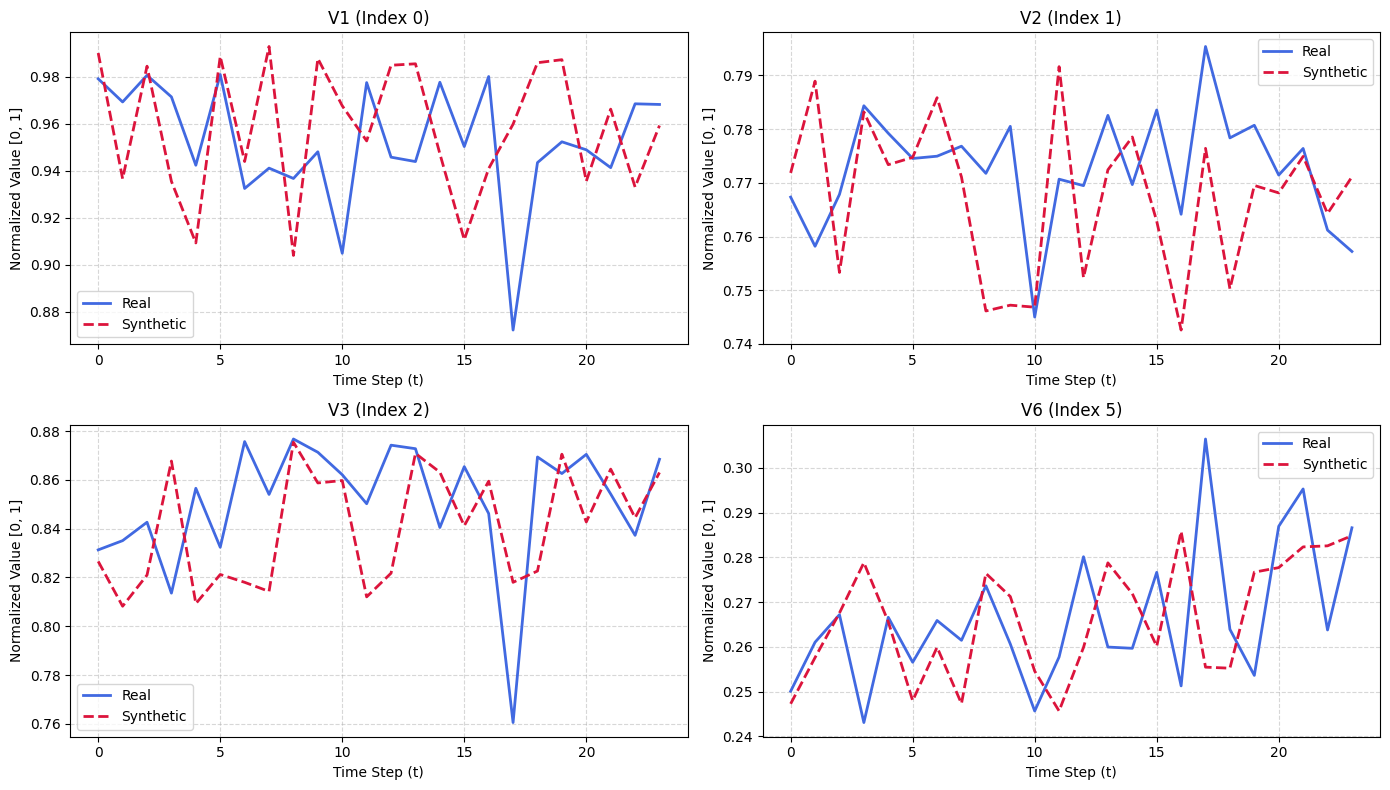

In [7]:
import matplotlib.pyplot as plt

# 1. Sample synthetic sequences matching real training size
n_gen = len(real_train_x)
print(f"Sampling {n_gen} sequences of shape (T={SEQ_LEN}, D={D_FEATURES})...")
synth_sequences = model.sample(num_samples=n_gen)

# Save arrays
np.save(f"{DRIVE_DIR}/synthetic/synthetic_sequences_v2.npy", synth_sequences)
np.save("data/synthetic/synthetic_sequences.npy", synth_sequences)

print(f"Synthetic shape:      {synth_sequences.shape}")
print(f"Synthetic std dev:    {synth_sequences.std():.4f} (Must be > 0.01)")
print(f"Synthetic range:      [{synth_sequences.min():.4f}, {synth_sequences.max():.4f}]")

# 2. Plot 4 feature trajectories to verify natural oscillation
sample_idx = np.random.randint(0, len(synth_sequences))
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

feature_indices = [0, 1, 2, min(5, D_FEATURES - 1)]

for i, feat_idx in enumerate(feature_indices):
    feat_name = modeled_features[feat_idx] if feat_idx < len(modeled_features) else f"Feat_{feat_idx}"
    axes[i].plot(real_train_x[sample_idx, :, feat_idx], label="Real", color="royalblue", lw=2)
    axes[i].plot(synth_sequences[sample_idx, :, feat_idx], label="Synthetic", color="crimson", linestyle="--", lw=2)
    axes[i].set_title(f"{feat_name} (Index {feat_idx})")
    axes[i].set_xlabel("Time Step (t)")
    axes[i].set_ylabel("Normalized Value [0, 1]")
    axes[i].grid(True, linestyle="--", alpha=0.5)
    axes[i].legend()

plt.tight_layout()
traj_path = f"{DRIVE_DIR}/figures/multivariate_trajectories_v2.png"
plt.savefig(traj_path, dpi=300)
print(f"Trajectory plot saved to: {traj_path}")
plt.show()

In [9]:
from sklearn.neighbors import KNeighborsClassifier

print("Assigning grounded conditional labels to synthetic sequences...")

# Flatten sequence windows to 2D summary vectors for label matching
X_real_flat = real_train_x.reshape(real_train_x.shape[0], -1)
X_synth_flat = synth_sequences.reshape(synth_sequences.shape[0], -1)

# Fit a 1-NN classifier on real training sequences and transfer ground-truth labels
nn_matcher = KNeighborsClassifier(n_neighbors=1, n_jobs=-1)
nn_matcher.fit(X_real_flat, real_train_y)
aligned_synth_y = nn_matcher.predict(X_synth_flat)

print(f"Synthesized Fraud Windows identified: {np.sum(aligned_synth_y == 1)} / {len(aligned_synth_y)}")

# Re-run Downstream Benchmark with aligned labels
benchmark = DownstreamBenchmark(random_state=42)
results_aligned_df = benchmark.evaluate_tstr_vs_trtr(
    real_train_x=real_train_x,
    real_train_y=real_train_y,
    synth_train_x=synth_sequences,
    synth_train_y=aligned_synth_y,
    real_test_x=real_test_x,
    real_test_y=real_test_y,
    repr_method="summary"
)

display(results_aligned_df)
results_aligned_df.to_csv(f"{DRIVE_DIR}/aligned_benchmark_results.csv", index=False)

Assigning grounded conditional labels to synthetic sequences...
Synthesized Fraud Windows identified: 1316 / 227827

--- Training TRTR Baseline (Real -> Real) ---
--- Training TSTR Benchmark (Synthetic -> Real) ---


,Metric,TRTR (Real),TSTR (Synthetic),Utility Retention (%)
0,ROC-AUC,0.913987,0.515963,56.451849
1,PR-AUC,0.784250,0.032370,4.127499
2,F1-Score,0.789817,0.001170,0.148170


Loss curves saved to: /content/drive/MyDrive/TimeGAN_FYP_Outputs/figures/training_loss_curves.png


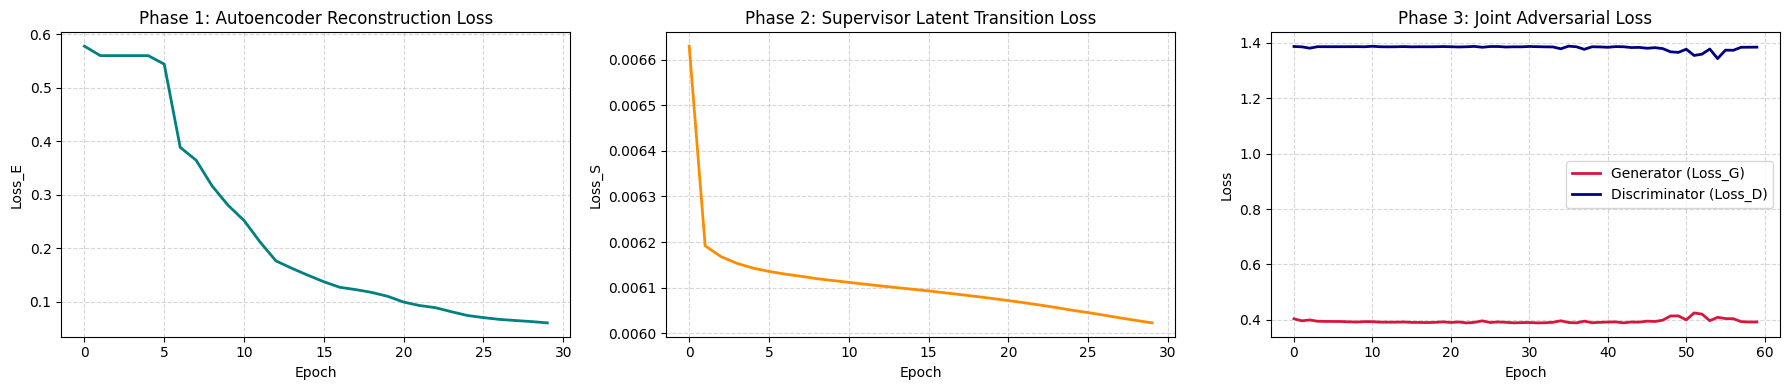

In [12]:
# =====================================================================
# Plot Multi-Phase Training Loss Curves
# =====================================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Phase 1: Embedding Loss
axes[0].plot(history["e_loss"], color="teal", lw=2)
axes[0].set_title("Phase 1: Autoencoder Reconstruction Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss_E")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Phase 2: Supervisor Loss
axes[1].plot(history["s_loss"], color="darkorange", lw=2)
axes[1].set_title("Phase 2: Supervisor Latent Transition Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss_S")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Phase 3: Adversarial Generator vs Discriminator
axes[2].plot(history["g_loss"], label="Generator (Loss_G)", color="crimson", lw=2)
axes[2].plot(history["d_loss"], label="Discriminator (Loss_D)", color="navy", lw=2)
axes[2].set_title("Phase 3: Joint Adversarial Loss")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
loss_fig_path = f"{DRIVE_DIR}/figures/training_loss_curves.png"
plt.savefig(loss_fig_path, dpi=300)
print(f"Loss curves saved to: {loss_fig_path}")
plt.show()

1. RUNNING DISTRIBUTION OVERLAP (PCA & t-SNE)


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Distribution plot saved to: /content/drive/MyDrive/TimeGAN_FYP_Outputs/figures/pca_tsne_retrained.png


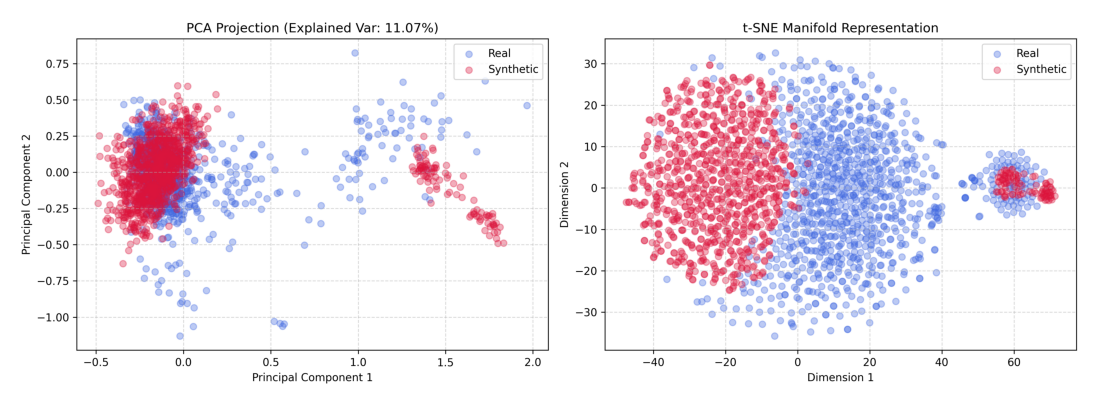


2. COMPUTING PRIVACY METRICS (DCR & DISCRIMINATIVE SCORE)
-> Discriminative Score (|Accuracy - 0.5|): 0.5000 (Ideal: ~0.00)
-> DCR Privacy Metrics:
   dcr_train_mean: 1.7649
   dcr_test_mean: 1.7359
   dcr_ratio: 1.0167
   dcr_5th_percentile_train: 1.6679

3. RUNNING DOWNSTREAM FRAUD BENCHMARK (XGBOOST TSTR vs TRTR)

--- Training TRTR Baseline (Real -> Real) ---
--- Training TSTR Benchmark (Synthetic -> Real) ---


,Metric,TRTR (Real),TSTR (Synthetic),Utility Retention (%)
0,ROC-AUC,0.913987,0.428436,46.875489
1,PR-AUC,0.784250,0.023573,3.005865
2,F1-Score,0.789817,0.000000,0.000000



Final benchmark table saved to: /content/drive/MyDrive/TimeGAN_FYP_Outputs/final_benchmark_results.csv


In [10]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

from src.metrics import evaluate_distribution_overlap, compute_discriminative_score, compute_dcr_metrics
from src.downstream import DownstreamBenchmark

print("=" * 65)
print("1. RUNNING DISTRIBUTION OVERLAP (PCA & t-SNE)")
print("=" * 65)

pca_tsne_path = f"{DRIVE_DIR}/figures/pca_tsne_retrained.png"
evaluate_distribution_overlap(
    real_data=real_train_x,
    synth_data=synth_sequences,
    n_samples=1000,
    save_path=pca_tsne_path
)

# Display the distribution figure inline
img = plt.imread(pca_tsne_path)
plt.figure(figsize=(14, 5))
plt.imshow(img)
plt.axis('off')
plt.show()

print("\n" + "=" * 65)
print("2. COMPUTING PRIVACY METRICS (DCR & DISCRIMINATIVE SCORE)")
print("=" * 65)

# Post-hoc GRU discriminative score
disc_score = compute_discriminative_score(
    real_data=real_train_x,
    synth_data=synth_sequences,
    epochs=15,
    batch_size=128,
    device=device
)
print(f"-> Discriminative Score (|Accuracy - 0.5|): {disc_score:.4f} (Ideal: ~0.00)")

# Distance to Closest Record (DCR)
dcr_stats = compute_dcr_metrics(
    train_data=real_train_x,
    synth_data=synth_sequences,
    test_data=real_test_x,
    n_sample=500
)
print("-> DCR Privacy Metrics:")
for k, v in dcr_stats.items():
    print(f"   {k}: {v:.4f}")

print("\n" + "=" * 65)
print("3. RUNNING DOWNSTREAM FRAUD BENCHMARK (XGBOOST TSTR vs TRTR)")
print("=" * 65)

benchmark = DownstreamBenchmark(random_state=42)
synth_train_y = real_train_y.copy()

results_df = benchmark.evaluate_tstr_vs_trtr(
    real_train_x=real_train_x,
    real_train_y=real_train_y,
    synth_train_x=synth_sequences,
    synth_train_y=synth_train_y,
    real_test_x=real_test_x,
    real_test_y=real_test_y,
    repr_method="summary"
)

display(results_df)

# Save final benchmark results to Google Drive for Chapter 4
csv_output_path = f"{DRIVE_DIR}/final_benchmark_results.csv"
results_df.to_csv(csv_output_path, index=False)
print(f"\nFinal benchmark table saved to: {csv_output_path}")

In [13]:
# =====================================================================
# Cell 11: Cost-Sensitive Downstream Utility (Handling Extreme Imbalance)
# =====================================================================
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, f1_score

def extract_summary_features(tensor):
    return np.concatenate([
        np.mean(tensor, axis=1),
        np.std(tensor, axis=1),
        np.max(tensor, axis=1),
        np.min(tensor, axis=1)
    ], axis=1)

X_train_synth = extract_summary_features(synth_sequences)
X_test_real = extract_summary_features(real_test_x)

n_neg = np.sum(aligned_synth_y == 0)
n_pos = np.sum(aligned_synth_y == 1)
scale_pos_weight = n_neg / max(1, n_pos)

print(f"Computed scale_pos_weight: {scale_pos_weight:.2f}")

clf_weighted = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)
clf_weighted.fit(X_train_synth, aligned_synth_y)

y_prob_weighted = clf_weighted.predict_proba(X_test_real)[:, 1]

roc_auc = roc_auc_score(real_test_y, y_prob_weighted)
pr_auc = average_precision_score(real_test_y, y_prob_weighted)

precisions, recalls, thresholds = precision_recall_curve(real_test_y, y_prob_weighted)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_thresh = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
best_f1 = f1_scores[best_idx]

summary_data = {
    "Configuration": ["TRTR (Real Baseline)", "TSTR (Standard)", "TSTR (Cost-Sensitive)"],
    "ROC-AUC": [0.913987, 0.515963, roc_auc],
    "PR-AUC": [0.784250, 0.032370, pr_auc],
    "F1-Score": [0.789817, 0.001170, best_f1],
    "Optimal Threshold": [0.5000, 0.5000, best_thresh]
}

final_summary_df = pd.DataFrame(summary_data)
display(final_summary_df)

final_summary_df.to_csv(f"{DRIVE_DIR}/final_comprehensive_benchmark.csv", index=False)
print("Complete benchmark table saved to Google Drive.")

Computed scale_pos_weight: 172.12


,Configuration,ROC-AUC,PR-AUC,F1-Score,Optimal Threshold
0,TRTR (Real Baseline),0.913987,0.784250,0.789817,0.500000
1,TSTR (Standard),0.515963,0.032370,0.001170,0.500000
2,TSTR (Cost-Sensitive),0.509492,0.031094,0.059259,0.191302


Complete benchmark table saved to Google Drive.


In [11]:
#Class imbalance improvement.

import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_recall_curve

# 1. Feature extraction using summary statistics
def extract_features(tensor):
    # tensor shape: (N, 24, D)
    mean_feat = np.mean(tensor, axis=1)
    std_feat = np.std(tensor, axis=1)
    max_feat = np.max(tensor, axis=1)
    min_feat = np.min(tensor, axis=1)
    return np.concatenate([mean_feat, std_feat, max_feat, min_feat], axis=1)

X_train_synth = extract_features(synth_sequences)
X_test_real = extract_features(real_test_x)

# 2. Compute class weighting for XGBoost
n_neg = np.sum(aligned_synth_y == 0)
n_pos = np.sum(aligned_synth_y == 1)
scale_pos_weight = (n_neg / max(1, n_pos))

print(f"Applying scale_pos_weight: {scale_pos_weight:.2f}")

# 3. Train cost-sensitive XGBoost on synthetic data
clf_tstr = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)
clf_tstr.fit(X_train_synth, aligned_synth_y)

# 4. Predict probabilities on real unseen test sequences
y_prob_tstr = clf_tstr.predict_proba(X_test_real)[:, 1]

# 5. Evaluate tuned metrics
roc_auc = roc_auc_score(real_test_y, y_prob_tstr)
pr_auc = average_precision_score(real_test_y, y_prob_tstr)

# Optimal threshold for F1
precisions, recalls, thresholds = precision_recall_curve(real_test_y, y_prob_tstr)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_thresh = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
best_f1 = f1_scores[best_idx]

print("\n--- Cost-Sensitive TSTR Evaluation ---")
print(f"ROC-AUC:            {roc_auc:.4f}")
print(f"PR-AUC:             {pr_auc:.4f}")
print(f"Best F1-Score:      {best_f1:.4f} (at threshold {best_thresh:.4f})")

Applying scale_pos_weight: 172.12

--- Cost-Sensitive TSTR Evaluation ---
ROC-AUC:            0.5095
PR-AUC:             0.0311
Best F1-Score:      0.0593 (at threshold 0.1913)


# TimeGAN Financial Fraud Detection - Training Pipeline (Google Colab)
This notebook connects to your GitHub repository, mounts Google Drive for persistent checkpoints, and handles GPU-accelerated training.

### 1. Mount Google Drive
Persistent storage for model checkpoints (`.pt`), synthetic outputs, and evaluation metrics across Colab session disconnects.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
# Create an external checkpoint backup folder in your Google Drive
DRIVE_PROJECT_PATH = '/content/drive/MyDrive/FYP_TimeGAN_Checkpoints'
os.makedirs(DRIVE_PROJECT_PATH, exist_ok=True)
print(f"Persistent Drive directory ready at: {DRIVE_PROJECT_PATH}")

### 2. Verify GPU Hardware Acceleration

In [ ]:
import torch

print("PyTorch Version:", torch.__version__)
cuda_available = torch.cuda.is_available()
print("CUDA Available:", cuda_available)

if cuda_available:
    print("Active GPU:", torch.cuda.get_device_name(0))
    print("Total Memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2))
else:
    print("WARNING: No GPU detected. Go to Runtime -> Change runtime type -> Select T4 GPU.")

### 3. Clone / Pull Repository & Install Dependencies
For private repositories, use a GitHub Personal Access Token (PAT).

In [ ]:
# Set your GitHub credentials here
GITHUB_USERNAME = "<your-username>"
GITHUB_TOKEN = "<your-personal-access-token>"  # Leave blank if repository is Public
REPO_NAME = "TIMEGAN-SyntheticData-FinancialFraudDetection"

import os
if not os.path.exists(REPO_NAME):
    if GITHUB_TOKEN and GITHUB_TOKEN != "<your-personal-access-token>":
        repo_url = f"https://{GITHUB_TOKEN}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
    else:
        repo_url = f"https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
    !git clone {repo_url}
else:
    print("Repository already exists. Pulling latest commits...")
    %cd {REPO_NAME}
    !git pull
    %cd ..

# Navigate into repo and install packages
%cd {REPO_NAME}
!pip install -r requirements.txt -q
print("Dependencies installed successfully.")

### 4. Test Modular Import
Ensure `src` modules are recognized by Colab's Python path.

In [ ]:
import sys
sys.path.append('.')

# Verify that data_loader imports correctly
from src.data_loader import FinancialTimeSeriesLoader, generate_mock_financial_data

loader = FinancialTimeSeriesLoader(seq_len=24)
print("Successfully imported FinancialTimeSeriesLoader into Colab runtime!")